# Lorenz example: joint state estimation and dynamics discovery

## Goal

Use the reusable `state_forecast` library to train a state estimator and dynamics
model together from noisy measurements. This notebook owns the Lorenz experiment;
the library owns the advance–correct loop, forecast loss, integration, and Adam training.

The saved outputs show a one-sensor run: only `u` is measured, while `v` and `w`
are inferred. The notebook trains from scratch in two phases, then evaluates
state recovery and forecasts on independent test trajectories. Choose one, two,
or three sensors in **Experiment settings** before rerunning.


## Setup

From the repository root, install the library and notebook dependencies in your Python environment:

```bash
python -m pip install -e ".[notebooks,test]"
python -m jupyter lab notebooks/lorenz.ipynb
```

Use the same environment as the notebook kernel. CPU execution is sufficient.

In [1]:
import copy
from dataclasses import asdict, replace
import json
import os
from pathlib import Path
import sys

candidates = (Path.cwd(), *Path.cwd().parents)
ROOT = next((path for path in candidates if (path / "state_forecast").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the repository root or its notebooks directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".mplconfig"))

import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from state_forecast import JointEstimator, ODEDynamics, TrainingConfig, fit
from examples.lorenz import (
    COEFFICIENT_NAMES, TRUE_COEFFICIENTS, Config, LorenzRate,
    evaluate, simulate,
)

%matplotlib inline
torch.set_num_threads(1)  # An example runtime choice, not a library side effect.
BLUE, ORANGE, GRAY, OLIVE = "#2563eb", "#c87516", "#8b95a5", "#707b32"
plt.rcParams.update({"font.size": 11, "figure.figsize": (11, 4.5),
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "grid.color": "#e4e7ec"})
print(f"PyTorch {torch.__version__}; NumPy {np.__version__}")

PyTorch 2.9.1+cpu; NumPy 2.5.3


### Experiment settings

This notebook trains from scratch using 256 training sequences, 64 validation
sequences, and 64 test sequences. Three forecast origins share one causal history.
Each forecast has 40 future targets, or 0.4 Lorenz time units.

Set `SENSORS` to `1` (measure `u`), `2` (measure `u,v`), or `3` (measure
`u,v,w`). The committed plots and metrics come from the default one-sensor run
with 800 initial and 800 refinement updates. Changing settings requires rerunning
training and all subsequent cells to refresh those outputs.

Checkpoint and evaluation files are written to `notebooks/outputs/lorenz/` and excluded from version
control. Outputs embedded in this notebook are retained in version control.
Environment variables can select sensors or shorten training for an execution check.


In [2]:
SENSORS = int(os.environ.get("LORENZ_SENSORS", "1"))  # 1: u; 2: u,v; 3: u,v,w
if SENSORS not in {1, 2, 3}:
    raise ValueError("SENSORS must be 1, 2, or 3.")
UPDATES = int(os.environ.get("LORENZ_UPDATES", "800"))
REFINEMENT_UPDATES = int(os.environ.get("LORENZ_REFINEMENT_UPDATES", "800"))
OUTPUT = Path(os.environ.get("LORENZ_OUTPUT", str(ROOT / "notebooks/outputs/lorenz")))
config = Config(sensors=SENSORS, updates=UPDATES, corrector_lr=0.0005)
torch.manual_seed(config.seed)
print(f"Sensors: {config.sensors}; dt: {config.dt}; noise std: {config.noise_std}")
print(f"Training/validation/test sequences: {config.train_sequences}/{config.val_sequences}/{config.test_sequences}")


Sensors: 1; dt: 0.01; noise std: 0.3
Training/validation/test sequences: 256/64/64


## Steps

### 1. Supply the Lorenz candidate dynamics

Write the state as $(u,v,w)$ and reserve $y$ for measurements. The simulator uses
the classical coefficients $(-10,10,28,-1,-8/3)$. The candidate family is

$$\dot u = a u + b v,\quad
\dot v = c u + d v - u w,\quad
\dot w = u v + e w.$$

`LorenzRate` is an example-specific module with five signed trainable parameters.
Its `forward` method is shown directly from its source below. The library imposes
no Lorenz equations: another rate module or a discrete state-transition module
can replace it.

**Assumptions:** The quadratic interaction coefficients are fixed in this example
as a structural prior. This is learning within a supplied term
family. With one sensor, two coordinates are unmeasured, so accurate `u`
forecasts alone do not establish recovery of `v`, `w`, or the coefficients.
With two sensors, fixing one interaction can anchor the unmeasured
coordinate's scale; fixing both is a stronger structural prior. With three
sensors, both interactions could instead be learned by changing `LorenzRate`.

In [3]:
import inspect
from IPython.display import Code
display(Code(inspect.getsource(LorenzRate), language="python"))

rate_model = LorenzRate()
dynamics = ODEDynamics(rate_model, dt=config.dt, integrator=config.integrator)
H = torch.eye(3)[:config.sensors]
fresh_model = JointEstimator(
    dynamics, H, hidden_width=config.hidden_width,
    correction_input_scale=20.0, correction_output_scale=10.0,
)
assert torch.count_nonzero(fresh_model.corrector[-1].weight) == 0
assert torch.count_nonzero(fresh_model.corrector[-1].bias) == 0
print("H =", H.tolist())
print("Initial signed coefficients:", rate_model.coefficients.detach().tolist())

class LorenzRate(nn.Module):
    """Example candidate family: five signed coefficients and fixed quadratic terms."""
    def __init__(self):
        super().__init__()
        self.coefficients = nn.Parameter(torch.tensor([-6.0, 6.0, 18.0, -0.5, -1.5]))

    def forward(self, state: Tensor) -> Tensor:
        u, v, w = state.unbind(-1)
        a, b, c, d, e = self.coefficients.unbind()
        return torch.stack((a * u + b * v, c * u + d * v - u * w, u * v + e * w), -1)

H = [[1.0, 0.0, 0.0]]
Initial signed coefficients: [-6.0, 6.0, 18.0, -0.5, -1.5]


### 2. Generate independent measurement sequences

`simulate` uses fine-step RK4, independently drawn initial conditions, a 3-unit
burn-in, and independent Gaussian sensor noise. Training and validation truth
are discarded. Only their measurement tensors are passed to `fit`.

With origins 60, 80, and 100 and horizon 40, each training sequence has 141
measurement times. The history ends at each saved origin; later measurements
serve as that origin's targets. Test truth is used only for evaluation.

In [4]:
sequence_length = max(config.origins) + config.horizon + 1
_, training_readings = simulate(config.train_sequences, sequence_length, config, config.seed + 1)
_, validation_readings = simulate(config.val_sequences, sequence_length, config, config.seed + 2)
training_measurements = torch.from_numpy(training_readings)
validation_measurements = torch.from_numpy(validation_readings)
print("Training measurements [sequence, time, sensor]:", tuple(training_measurements.shape))
print("Validation measurements:", tuple(validation_measurements.shape))
print("Forecast origins per sequence:", config.origins)

Training measurements [sequence, time, sensor]: (256, 141, 1)
Validation measurements: (64, 141, 1)
Forecast origins per sequence: (60, 80, 100)


### 3. Train the general learning system

The library minimizes future measurement MSE, $L=L_{\mathrm{future}}$, and
updates dynamics and corrector parameters jointly. Current disagreement is
logged as a diagnostic only: matching an already assimilated noisy measurement
can discourage denoising and bias learned dynamics. Shared history is processed
once, and the full gradient path to early corrections is retained.

The callback records Lorenz coefficients and checkpoint files; these are example
concerns. The first training phase uses 800 updates. Refinement restores the best
model and creates a fresh Adam optimizer for another 800 updates with lower rates.

In [5]:
model = fresh_model
initial_state = copy.deepcopy(model.state_dict())
phases = [("initial", UPDATES, 0.04, 0.0005)]
if REFINEMENT_UPDATES > 0:
    phases.append(("refinement", REFINEMENT_UPDATES, 0.02, 0.00025))
previous_checkpoint = None

for phase, updates, dynamics_lr, corrector_lr in phases:
    model.requires_grad_(True)
    phase_config = replace(config, updates=updates, dynamics_lr=dynamics_lr,
                           corrector_lr=corrector_lr)
    settings = TrainingConfig(
        origins=tuple(config.origins), horizon=config.horizon,
        updates=updates, batch_size=config.batch_size,
        dynamics_lr=dynamics_lr, corrector_lr=corrector_lr,
        validate_every=config.validate_every,
        seed=config.seed + 20,
    )
    phase_folder = OUTPUT / phase
    phase_folder.mkdir(parents=True, exist_ok=True)
    phase_history = []

    def record(progress):
        row = progress.record
        row["coefficients"] = model.dynamics.rate_model.coefficients.detach().tolist()
        phase_history.append(row)
        print(f"{phase}: update {row['step']:4d}, validation loss {row['val_loss']:.4f}")
        (phase_folder / "training.json").write_text(json.dumps(phase_history, indent=2))
        torch.save({"model": progress.best_state, "initial_model": initial_state,
                    "config": asdict(phase_config), "best_step": progress.best_step,
                    "warm_start": str(previous_checkpoint) if previous_checkpoint else None,
                    "library": "state_forecast"}, phase_folder / "checkpoint.pt")

    result = fit(model, training_measurements, validation_measurements,
                 settings, on_validation=record)
    previous_checkpoint = phase_folder / "checkpoint.pt"
    config = phase_config

history = result.history
best_step = result.best_step


initial: update    0, validation loss 53.4127


initial: update  100, validation loss 3.1061


initial: update  200, validation loss 2.1935


initial: update  300, validation loss 1.3144


initial: update  400, validation loss 1.0398


...

refinement: update  400, validation loss 0.5621


refinement: update  500, validation loss 0.5123


refinement: update  600, validation loss 0.4873


refinement: update  700, validation loss 0.4286


refinement: update  800, validation loss 0.4318


### 4. Inspect training and coefficients

The learning curve below shows the final phase. Validation uses 64 independent
sequences; the training diagnostic uses a fixed 64-sequence subset. The detailed
initial-phase history remains in its saved artifacts.

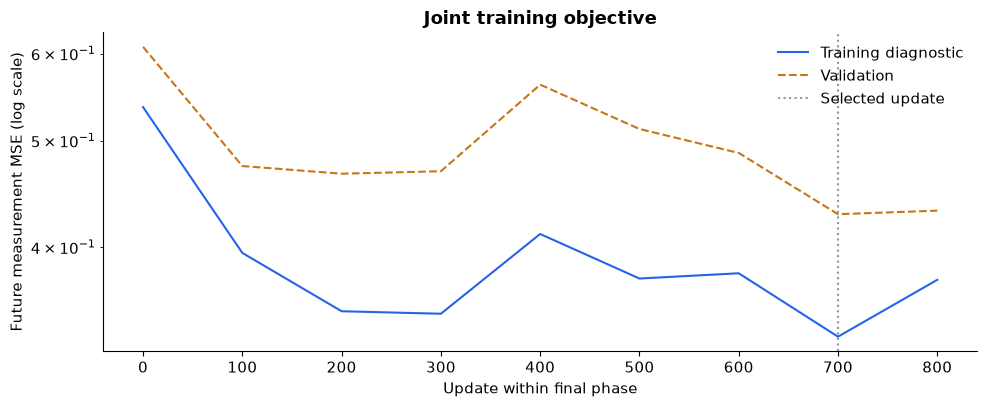

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.2))
steps = [row["step"] for row in history]
ax.semilogy(steps, [row["train_loss"] for row in history], color=BLUE, label="Training diagnostic")
ax.semilogy(steps, [row["val_loss"] for row in history], color=ORANGE, linestyle="--", label="Validation")
ax.axvline(best_step, color=GRAY, linestyle=":", label="Selected update")
ax.set(xlabel="Update within final phase", ylabel="Future measurement MSE (log scale)",
       title="Joint training objective")
ax.grid(axis="y")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

| Candidate contribution | True | Learned | Relative error |
|---|---:|---:|---:|
| u in du/dt | -10.0000 | -9.9230 | 0.77% |
| v in du/dt | 10.0000 | 10.8726 | 8.73% |
| u in dv/dt | 28.0000 | 21.3546 | 23.73% |
| v in dv/dt | -1.0000 | -0.8105 | 18.95% |
| w in dw/dt | -2.6667 | -3.1966 | 19.87% |

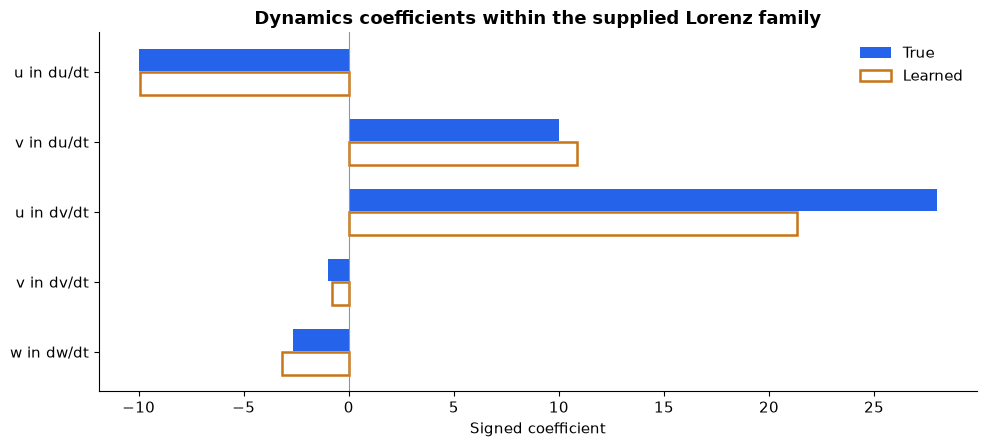

In [7]:
learned_coefficients = model.dynamics.rate_model.coefficients.detach().cpu().numpy()
relative_errors = 100 * np.abs((learned_coefficients - TRUE_COEFFICIENTS) / TRUE_COEFFICIENTS)
rows = ["| Candidate contribution | True | Learned | Relative error |", "|---|---:|---:|---:|"]
for name, true, learned, error in zip(COEFFICIENT_NAMES, TRUE_COEFFICIENTS,
                                    learned_coefficients, relative_errors):
    rows.append(f"| {name} | {true:.4f} | {learned:.4f} | {error:.2f}% |")
display(Markdown("\n".join(rows)))

positions = np.arange(5)
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.barh(positions - 0.17, TRUE_COEFFICIENTS, height=0.32, color=BLUE, label="True")
ax.barh(positions + 0.17, learned_coefficients, height=0.32,
        facecolor="white", edgecolor=ORANGE, linewidth=1.8, label="Learned")
ax.axvline(0, color=GRAY, linewidth=0.8)
ax.set(yticks=positions, yticklabels=COEFFICIENT_NAMES, xlabel="Signed coefficient",
       title="Dynamics coefficients within the supplied Lorenz family")
ax.invert_yaxis()
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### 5. Evaluate on held-out trajectories

Parameters are frozen. Evaluation uses 64 independent test sequences and four
origins per sequence, forecasting as far as 2 time units. State errors exclude
the first 0.8 units of initial convergence. Four origins share each trajectory;
they do not constitute 256 independent trajectories.

Persistence repeats the latest noisy measurement. The fixed-corrector comparison
uses the same learned dynamics with the neural correction disabled; it is an
ablation rather than a separately trained model.

After training, rerun the next cell to refresh evaluation without retraining.
It reloads the example helpers so a running kernel picks up code fixes. If the
kernel has restarted, run **Setup** first, then this cell: it restores the most
recent phase checkpoint from `OUTPUT` (the default output folder if unset).
One sensor measures `u`; two measure `u,v`; three measure `u,v,w`.


In [8]:
# Refresh helpers without restarting the kernel or losing the trained model.
import importlib
import examples.lorenz as lorenz_example
lorenz_example = importlib.reload(lorenz_example)

# Also allow resuming after a kernel restart: run Setup, then this cell.
if "model" not in globals():
    OUTPUT = globals().get("OUTPUT", Path(os.environ.get(
        "LORENZ_OUTPUT", str(ROOT / "notebooks/outputs/lorenz"))))
    checkpoints = [path for phase in ("initial", "refinement")
                   if (path := OUTPUT / phase / "checkpoint.pt").is_file()]
    if not checkpoints:
        raise FileNotFoundError(f"No completed training checkpoint under {OUTPUT}.")
    checkpoint_path = max(checkpoints, key=lambda path: path.stat().st_mtime_ns)
    model, config, saved = lorenz_example.load_checkpoint(checkpoint_path)
    initial_state = saved["initial_model"]
    history = json.loads((checkpoint_path.parent / "training.json").read_text())
    best_step = saved["best_step"]
    print(f"Restored trained model from {checkpoint_path}; {config.sensors} sensor(s).")

model.eval()
model.requires_grad_(False)
evaluation_folder = OUTPUT / "evaluation"
evaluation_folder.mkdir(parents=True, exist_ok=True)
metrics = lorenz_example.evaluate(model, initial_state, config, evaluation_folder)
arrays = np.load(evaluation_folder / "evaluation.npz")

truth, readings, estimated_states = arrays["truth"], arrays["measurements"], arrays["filtered"]
forecast_states, forecast_truth = arrays["forecasts"], arrays["forecast_truth"]
sample = 0  # Predetermined first test trajectory, not selected by performance.
print("State RMSE after warm-up (u, v, w):", np.round(metrics["state_rmse_after_0.8_time_units"], 4))
print("Forecast sensor RMSE averaged over first 0.4 time units:",
      round(metrics["forecast_sensor_rmse_first_0.4_time_units"], 4))
print("Persistence sensor RMSE over the same horizon:",
      round(metrics["persistence_sensor_rmse_first_0.4_time_units"], 4))

State RMSE after warm-up (u, v, w): [0.2181 0.6802 6.6273]
Forecast sensor RMSE averaged over first 0.4 time units: 0.4445
Persistence sensor RMSE over the same horizon: 6.4942


### 6. Reconstruct the attractor and current state

Both attractor panels use the same coordinate ranges and camera. The time traces
show measured coordinates alongside the corrected estimates. Measurements enter
the advance–correct loop at each time; true states enter only these evaluation plots.

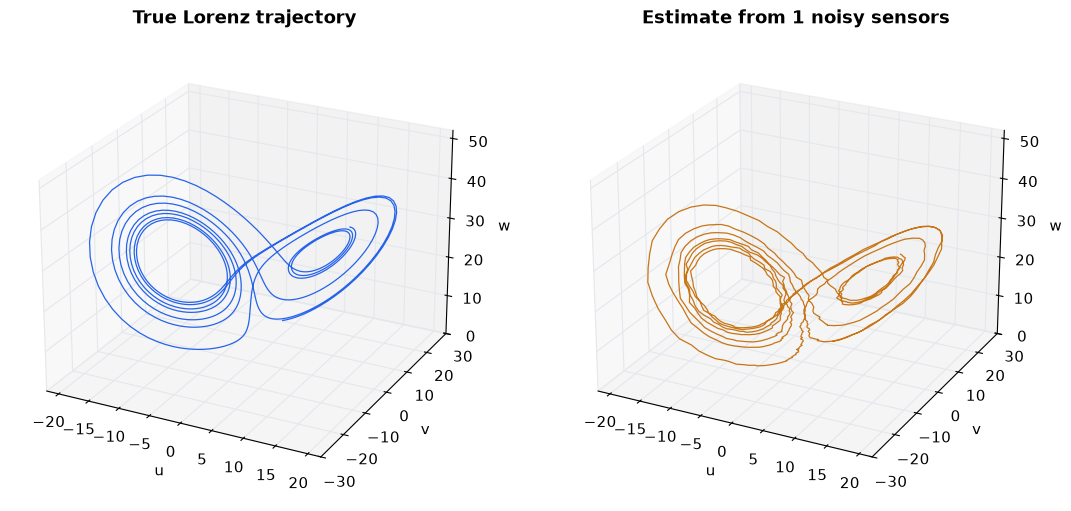

In [9]:
fig = plt.figure(figsize=(11, 5), layout="constrained")
for index, (states, color, title) in enumerate([
        (truth[sample, 80:], BLUE, "True Lorenz trajectory"),
        (estimated_states[sample, 80:], ORANGE, f"Estimate from {config.sensors} noisy sensors")], 1):
    ax = fig.add_subplot(1, 2, index, projection="3d")
    ax.plot(*states.T, color=color, linewidth=0.9)
    ax.set(xlabel="u", ylabel="v", zlabel="w", xlim=(-22, 22),
           ylim=(-30, 30), zlim=(0, 52), title=title)
    ax.view_init(elev=24, azim=-63)
plt.show()

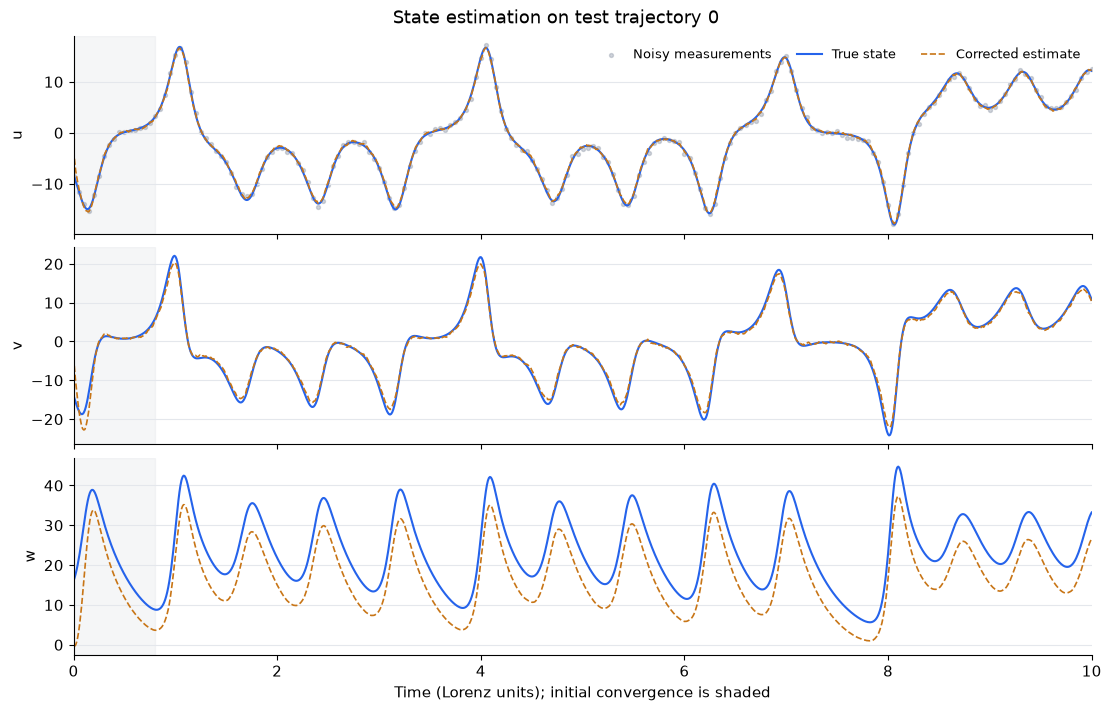

In [10]:
times = np.arange(truth.shape[1]) * config.dt
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True, layout="constrained")
for component, ax in enumerate(axes):
    if component < config.sensors:
        ax.scatter(times[::5], readings[sample, ::5, component], color=GRAY,
                   alpha=0.4, s=8, label="Noisy measurements")
    ax.plot(times, truth[sample, :, component], color=BLUE, linewidth=1.5, label="True state")
    ax.plot(times, estimated_states[sample, :, component], color=ORANGE,
            linewidth=1.2, linestyle="--", label="Corrected estimate")
    ax.axvspan(0, 0.8, color=GRAY, alpha=0.08)
    ax.set_ylabel(("u", "v", "w")[component])
    ax.grid(axis="y")
axes[0].legend(ncol=3, frameon=False, fontsize=9)
axes[-1].set(xlabel="Time (Lorenz units); initial convergence is shaded", xlim=(0, times[-1]))
fig.suptitle("State estimation on test trajectory 0")
plt.show()

### 7. Forecast from time zero

The last assimilated measurement is at local time zero. The forecast below is
recomputed directly with the library from its complete measurement prefix. No
positive-time measurement enters this forecast. Shading indicates the training horizon.

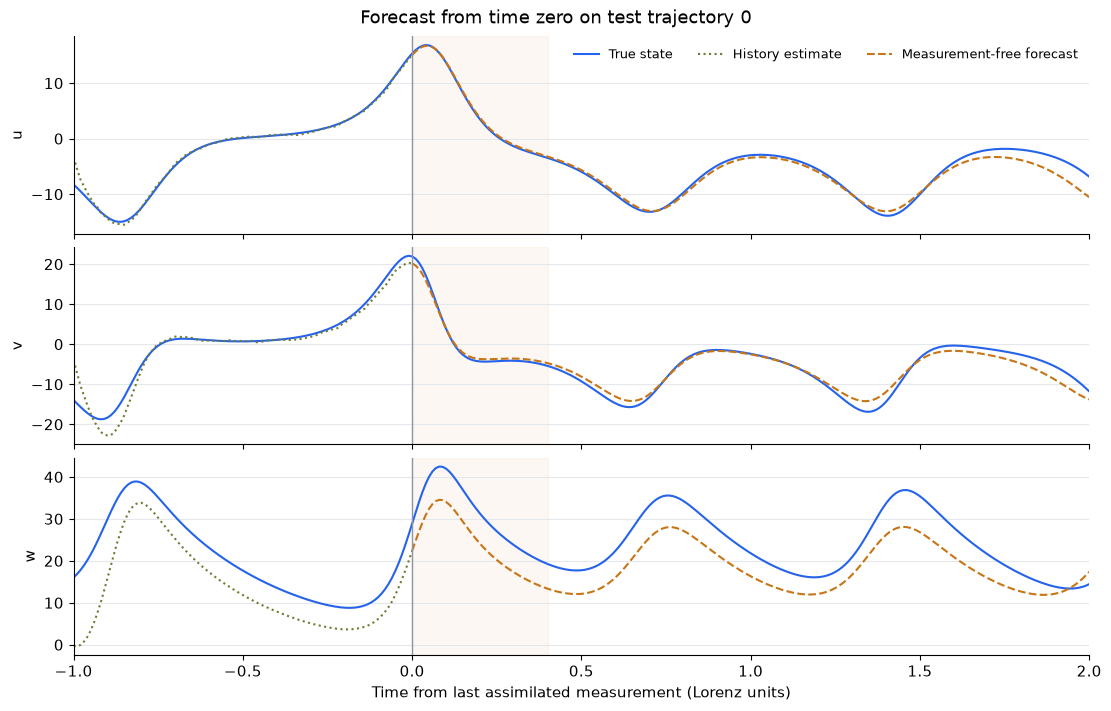

In [11]:
origin, horizon = 100, 200
prefix = torch.from_numpy(readings[sample:sample + 1, :origin + 1])
with torch.no_grad():
    latest_corrected = model.filter(prefix)[:, -1]
    future = model.forecast(latest_corrected.clone(), horizon)[0].cpu().numpy()
forecast_with_origin = np.concatenate([latest_corrected.cpu().numpy(), future])
forecast_times = np.arange(horizon + 1) * config.dt
history_times = (np.arange(origin + 1) - origin) * config.dt
all_times = (np.arange(origin + horizon + 1) - origin) * config.dt

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True, layout="constrained")
for component, ax in enumerate(axes):
    ax.plot(all_times, truth[sample, :len(all_times), component], color=BLUE, label="True state")
    ax.plot(history_times, estimated_states[sample, :origin + 1, component],
            color=OLIVE, linestyle=":", label="History estimate")
    ax.plot(forecast_times, forecast_with_origin[:, component], color=ORANGE,
            linestyle="--", label="Measurement-free forecast")
    ax.axvline(0, color=GRAY, linewidth=1)
    ax.axvspan(0, config.horizon * config.dt, color=ORANGE, alpha=0.05)
    ax.set_ylabel(("u", "v", "w")[component])
    ax.grid(axis="y")
axes[0].legend(ncol=3, frameon=False, fontsize=9)
axes[-1].set(xlabel="Time from last assimilated measurement (Lorenz units)", xlim=(-1, 2))
fig.suptitle("Forecast from time zero on test trajectory 0")
plt.show()

### 8. Inspect forecast error over lead time

The curve aggregates all test sequences and origins rather than relying on one
sample path. These are RMSE curves, not uncertainty intervals. Accuracy at leads
beyond the training horizon has not been optimized by that horizon's loss.

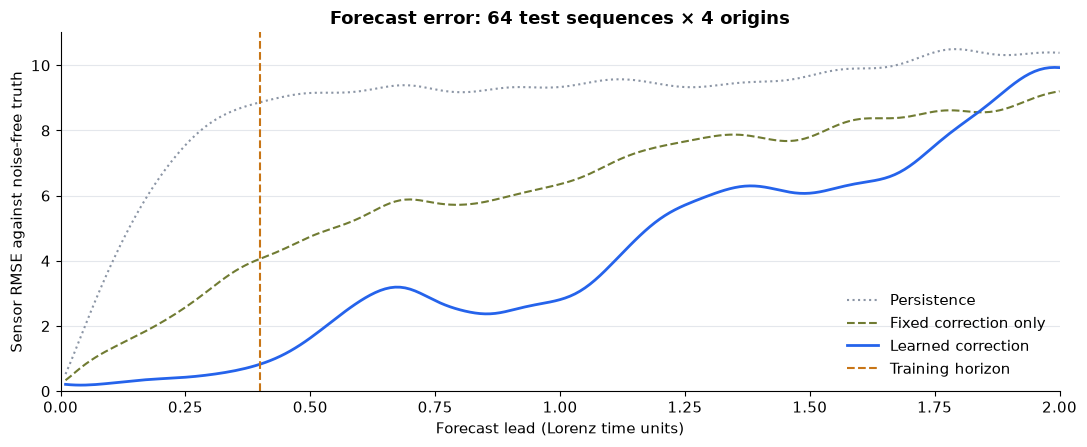

In [12]:
lead_times = np.arange(1, len(arrays["lead_rmse"]) + 1) * config.dt
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(lead_times, arrays["persistence_rmse"], color=GRAY, linestyle=":", label="Persistence")
ax.plot(lead_times, arrays["fixed_lead_rmse"], color=OLIVE, linestyle="--", label="Fixed correction only")
ax.plot(lead_times, arrays["lead_rmse"], color=BLUE, linewidth=2, label="Learned correction")
ax.axvline(config.horizon * config.dt, color=ORANGE, linestyle="--", label="Training horizon")
ax.set(xlabel="Forecast lead (Lorenz time units)", ylabel="Sensor RMSE against noise-free truth",
       title=f"Forecast error: {config.test_sequences} test sequences × 4 origins", xlim=(0, 2), ylim=(0, None))
ax.grid(axis="y")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Checks

Verify causality, evaluation-array agreement, and metric calculations directly.
Changing measurements after an origin must not alter that origin's forecast.
The numerical agreement check compares a single forecast with the batch
evaluation output with a small float32 tolerance: single and batched operations
can round differently. The causality check still requires exact equality.
Library unit tests also cover gradient flow and systems with
state dimensions other than three.

In [13]:
altered = readings[sample:sample + 1].copy()
altered[:, origin + 1:] += 100
with torch.no_grad():
    altered_origin = model.filter(torch.from_numpy(altered[:, :origin + 1]))[:, -1]
    altered_forecast = model.forecast(altered_origin, horizon)[0].cpu().numpy()
np.testing.assert_array_equal(future, altered_forecast)
origin_index = list(arrays["evaluation_origins"]).index(origin)
# Single-trajectory and batched float32 operations can round differently.
np.testing.assert_allclose(future, forecast_states[sample, origin_index], rtol=1e-5, atol=1e-5)
calculated_rmse = float(np.sqrt(np.mean(
    (forecast_states[:, :, :40, :config.sensors] - forecast_truth[:, :, :40, :config.sensors])**2)))
np.testing.assert_allclose(calculated_rmse, metrics["forecast_sensor_rmse_first_0.4_time_units"])
assert all(not parameter.requires_grad for parameter in model.parameters())
print("Passed: causal forecast, saved-array agreement, RMSE calculation, and frozen parameters.")

Passed: causal forecast, saved-array agreement, RMSE calculation, and frozen parameters.


In [14]:
display(Markdown(
    f"This run has horizon-averaged sensor RMSE **{calculated_rmse:.3f}** versus "
    f"**{metrics['persistence_sensor_rmse_first_0.4_time_units']:.3f}** for persistence. "
    f"The largest coefficient relative error is **{max(metrics['coefficient_relative_error_percent']):.1f}%**. "
    "Good measurement forecasts do not guarantee exact state or coefficient recovery. "
    + ("Unmeasured coordinates can remain biased. " if config.sensors < 3 else "") +
    "These are single-seed synthetic results."
))

This run has horizon-averaged sensor RMSE **0.445** versus **6.494** for persistence. The largest coefficient relative error is **23.7%**. Good measurement forecasts do not guarantee exact state or coefficient recovery. Unmeasured coordinates can remain biased. These are single-seed synthetic results.

## Next Steps

To use a different system, replace `LorenzRate` and the data generator, supply its
fixed observation matrix, and call the same `JointEstimator` and `fit` functions.
A discrete transition can be supplied directly instead of using `ODEDynamics`.
Use `state_projection` only when the system requires a differentiable physical constraint.

For online use, start with `posterior = None`, call
`model.assimilate(measurement, posterior)` as measurements arrive, and call
`model.forecast(posterior.clone(), horizon)` under `torch.no_grad()` to predict.

Generated artifacts are under `OUTPUT`: phase checkpoints and training logs,
plus evaluation metrics and arrays. Example equations and assumptions are in `examples/lorenz.py`;
generic learning code is in `state_forecast/`. The original simulator follows
[Lorenz (1963)](https://doi.org/10.1175/1520-0469%281963%29020%3C0130%3ADNF%3E2.0.CO%3B2).